# 04 · Neural network (Optuna-tuned) with SHAP explanations

A small feed-forward network for both tasks, tuned with Optuna and trained with class weights. For the binary model the decision threshold is chosen on the validation set by F2 score (recall-weighted); the selected threshold is 0.40. SHAP (KernelExplainer) explains both models.

*Outputs below are from the original Google Colab run used in the paper. To rerun, put the three BCSC files in `data/` (see `data/README.md`).*

## Binary classification

In [ ]:
######################### 2-CLASS DATA PREP FOR ANN #########################
import pandas as pd
import numpy as np

df_1 = pd.read_csv('../data/bcsc_risk_factors_summarized1_092020.csv')
df_2 = pd.read_csv('../data/bcsc_risk_factors_summarized2_092020.csv')
df_3 = pd.read_csv('../data/bcsc_risk_factors_summarized3_092020.csv')

# Concatenate
df = pd.concat([df_1, df_2, df_3], ignore_index=True)
print("Raw shape:", df.shape)

# DROP UNUSED COLUMNS "year" and "count"
df = df.drop(columns=['year', 'count'])
print("After dropping year & count:", df.shape)

# Make everything categorical
df = df.astype('category')

# Replace 9 with NaN in all columns EXCEPT age_group_5_years
cols_except_age = df.columns[df.columns != 'age_group_5_years']
df[cols_except_age] = df[cols_except_age].replace(9, np.nan)

# Drop rows where target (breast_cancer_history) is NaN
df = df.dropna(subset=['breast_cancer_history'])

df = df[df['breast_cancer_history'].isin([0, 1])].copy()

missing_info = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing %': (df.isna().sum() / len(df)) * 100
})
print("\nMissing info:")
print(missing_info)

# Fill NaN in each remaining column with the mode (except target)
for col in df.columns:
    if col != 'breast_cancer_history':
        df[col].fillna(df[col].mode()[0], inplace=True)

print("\nShape after filling NaNs:", df.shape)

# One-hot encoding for race_eth
df = pd.get_dummies(df, columns=['race_eth'], drop_first=True)

# Convert any bool columns to int
bool_cols = df.select_dtypes('bool').columns
df[bool_cols] = df[bool_cols].astype(int)

print("\nDtypes after get_dummies and bool→int:")
print(df.dtypes.head(15))

# 11) Define X and y for 2-class ANN
target_col = 'breast_cancer_history'

# y = binary labels 0/1
y = df[target_col].astype('int32')

# X = all other columns
X = df.drop(columns=[target_col])

X = X.astype('float32')

print("\nFinal X shape:", X.shape)
print("Final y value counts:")
print(y.value_counts())

Saving bcsc_risk_factors_summarized1_092020.csv to bcsc_risk_factors_summarized1_092020.csv
Saving bcsc_risk_factors_summarized3_092020.csv to bcsc_risk_factors_summarized3_092020.csv
Saving bcsc_risk_factors_summarized2_092020.csv to bcsc_risk_factors_summarized2_092020.csv
Raw shape: (1522340, 13)
After dropping year & count: (1522340, 11)



Missing info:
                       Missing Count  Missing %
age_group_5_years                  0   0.000000
race_eth                       74699   6.269651
first_degree_hx                37109   3.114640
age_menarche                  529232  44.419601
age_first_birth               234599  19.690408
BIRADS_breast_density         144193  12.102434
current_hrt                   124688  10.465337
menopaus                      105394   8.845949
bmi_group                     309681  25.992204
biophx                         22425   1.882179
breast_cancer_history              0   0.000000

Shape after filling NaNs: (1191438, 11)

Dtypes after get_dummies and bool→int:
age_group_5_years        category
first_degree_hx          category
age_menarche             category
age_first_birth          category
BIRADS_breast_density    category
current_hrt              category
menopaus                 category
bmi_group                category
biophx                   category
breast_cancer_history 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 8.1 MB/s eta 0:00:00


Train shape: (762520, 14)  Val shape: (190630, 14)  Test shape: (238288, 14)
Class weights: {0: 0.6143577893690289, 1: 2.6861213073405805}



Best trial: 1
Best value (F2): 0.6429067116090017
Best params: {'n_units1': 96, 'n_units2': 48, 'dropout1': 0.2958940049738683, 'dropout2': 0.15636688687681746, 'batch_size': 256}


Epoch 1/200
2979/2979 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - accuracy: 0.5989 - auc_pr: 0.3115 - auc_roc: 0.6809 - loss: 0.6414 - precision: 0.2762 - recall: 0.6877 - val_accuracy: 0.6907 - val_auc_pr: 0.4240 - val_auc_roc: 0.7941 - val_loss: 0.5491 - val_precision: 0.3520 - val_recall: 0.7866
Epoch 2/200
2979/2979 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.6828 - auc_pr: 0.4035 - auc_roc: 0.7813 - loss: 0.5584 - precision: 0.3442 - recall: 0.7768 - val_accuracy: 0.6933 - val_auc_pr: 0.4289 - val_auc_roc: 0.7984 - val_loss: 0.5356 - val_precision: 0.3548 - val_recall: 0.7917
Epoch 3/200
2979/2979 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.6825 - auc_pr: 0.4125 - auc_roc: 0.7886 - loss: 0.5498 - precision: 0.3462 - recall: 0.7927 - val_accuracy: 0.6988 - val_auc_pr: 0.4311 - val_auc_roc: 0.8007 - val_loss: 0.5261 - val_precision: 0.3592 - val_recall: 0.7889
Epoch 4/200
2979/2979 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.6841 - auc_pr: 0.4169 - auc_roc: 0.7921 - loss: 0.5462

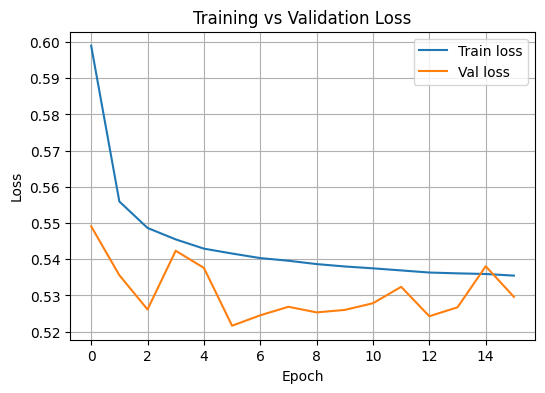

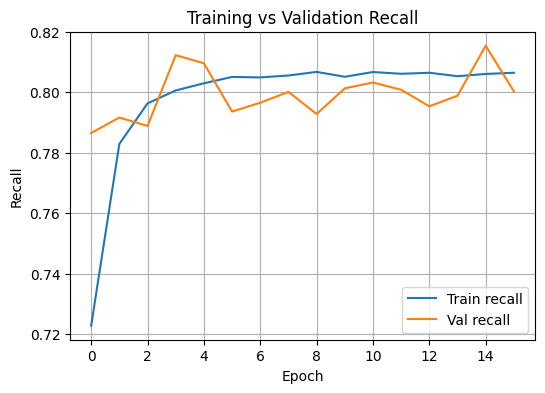

In [ ]:
# ANN + OPTUNA (BINARY VERSION)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    recall_score,
    precision_score,
    fbeta_score,
    roc_curve,
    precision_recall_curve,
    auc
)

import optuna
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Split: Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print("Train shape:", X_tr.shape, " Val shape:", X_val.shape, " Test shape:", X_test.shape)

# Class weights (for recall / Type II error)
classes = np.unique(y_tr)
cw = compute_class_weight(class_weight='balanced', classes=classes, y=y_tr)
class_weight = {int(c): float(w) for c, w in zip(classes, cw)}
print("Class weights:", class_weight)

input_dim = X_tr.shape[1]

# 5) OPTUNA: objective function
def objective(trial):
    tf.keras.backend.clear_session()

    # Hyperparameters
    n_units1 = trial.suggest_int("n_units1", 32, 96, step=32)
    n_units2 = trial.suggest_int("n_units2", 16, 48, step=16)
    dropout1 = trial.suggest_float("dropout1", 0.1, 0.5)
    dropout2 = trial.suggest_float("dropout2", 0.1, 0.5)
    batch_size = trial.suggest_categorical("batch_size", [128, 256, 512])

    lr = 0.0001

    # Build model
    model_tmp = Sequential([
        Dense(n_units1, activation='relu', input_dim=input_dim),
        Dropout(dropout1),
        Dense(n_units2, activation='relu'),
        Dropout(dropout2),
        Dense(1, activation='sigmoid')  # binary classification
    ])

    optimizer = Adam(learning_rate=lr)

    model_tmp.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=[tf.keras.metrics.Recall(name='recall')]
    )

    early_stop_opt = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    # Train candidate model
    history_tmp = model_tmp.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=batch_size,
        callbacks=[early_stop_opt],
        class_weight=class_weight,
        verbose=0
    )

    # Evaluate
    y_proba_val_tmp = model_tmp.predict(X_val, verbose=0).ravel()
    y_hat_val_tmp = (y_proba_val_tmp >= 0.5).astype(int)

    f2 = fbeta_score(y_val, y_hat_val_tmp, beta=2, zero_division=0)

    return f2

# Optuna search
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

print("\nBest trial:", study.best_trial.number)
print("Best value (F2):", study.best_value)
print("Best params:", study.best_params)

best_params = study.best_params

# Build the model using Optuna params
tf.keras.backend.clear_session()

model = Sequential([
    Dense(best_params["n_units1"], activation='relu', input_dim=input_dim),
    Dropout(best_params["dropout1"]),
    Dense(best_params["n_units2"], activation='relu'),
    Dropout(best_params["dropout2"]),
    Dense(1, activation='sigmoid')
])

optimizer = Adam(learning_rate=0.0001)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.AUC(name='auc_roc'),
        tf.keras.metrics.AUC(name='auc_pr', curve='PR')
    ]
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train model
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=best_params["batch_size"],
    callbacks=[early_stop],
    class_weight=class_weight,
    verbose=1
)

# PLOTS

# Loss
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

# Recall
plt.figure(figsize=(6,4))
plt.plot(history.history['recall'], label='Train recall')
plt.plot(history.history['val_recall'], label='Val recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.title('Training vs Validation Recall')
plt.legend()
plt.grid(True)
plt.show()

5958/5958 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step

Threshold tuning on VALIDATION set:
thr	Recall	Precision	F2
0.10	0.989	0.221		0.583
0.15	0.977	0.243		0.609
0.20	0.961	0.263		0.628
0.25	0.943	0.280		0.640
0.30	0.923	0.295		0.648
0.35	0.902	0.310		0.653
0.40	0.872	0.326		0.653
0.45	0.836	0.342		0.649
0.50	0.794	0.361		0.640
0.55	0.730	0.383		0.618
0.60	0.654	0.409		0.584
0.65	0.554	0.436		0.526
0.70	0.416	0.467		0.425
0.75	0.201	0.512		0.229
0.80	0.034	0.549		0.042
0.85	0.000	0.000		0.000
0.90	0.000	0.000		0.000

Best VALIDATION threshold by F2: {'thr': np.float64(0.4), 'rec': 0.8720831924247548, 'prec': 0.3255278189793922, 'f2': 0.6528563652704464}

=== VALIDATION RESULTS (thr = 0.40) ===
Confusion matrix (VAL):
 [[91030 64116]
 [ 4539 30945]]
Validation accuracy: 0.6399
Validation classification report:
              precision    recall  f1-score   support

           0       0.95      0.59      0.73    155146
           1       0.33      0.87      0.47     35484

    accuracy            

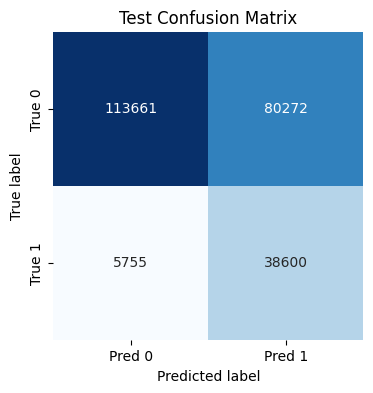

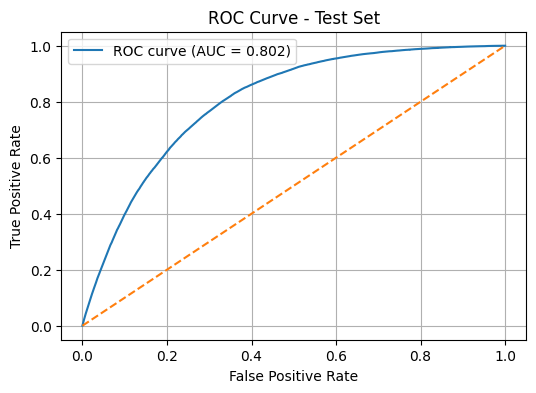

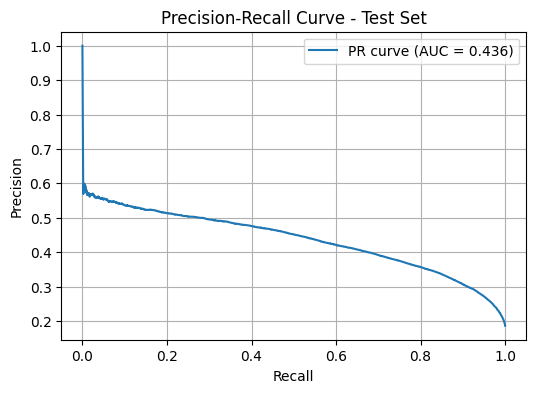

In [ ]:
# Validation:

y_proba_val = model.predict(X_val).ravel()

thresholds = np.linspace(0.1, 0.9, 17)
print("\nThreshold tuning on VALIDATION set:")
print("thr\tRecall\tPrecision\tF2")

best_thr_info = {"thr": None, "rec": -1, "prec": -1, "f2": -1}

for t in thresholds:
    y_hat_val = (y_proba_val >= t).astype(int)
    rec = recall_score(y_val, y_hat_val, zero_division=0)
    prec = precision_score(y_val, y_hat_val, zero_division=0)
    f2 = fbeta_score(y_val, y_hat_val, beta=2, zero_division=0)

    print(f"{t:.2f}\t{rec:.3f}\t{prec:.3f}\t\t{f2:.3f}")

    if f2 > best_thr_info["f2"]:
        best_thr_info = {"thr": t, "rec": rec, "prec": prec, "f2": f2}

best_thr = best_thr_info["thr"]
print("\nBest VALIDATION threshold by F2:", best_thr_info)

# metrics
y_hat_val_best = (y_proba_val >= best_thr).astype(int)

cm_val = confusion_matrix(y_val, y_hat_val_best)
val_acc = (y_hat_val_best == y_val).mean()

print(f"\n=== VALIDATION RESULTS (thr = {best_thr:.2f}) ===")
print("Confusion matrix (VAL):\n", cm_val)
print(f"Validation accuracy: {val_acc:.4f}")
print("Validation classification report:")
print(classification_report(y_val, y_hat_val_best))

# TEST SET:

y_proba_test = model.predict(X_test).ravel()
y_hat_test = (y_proba_test >= best_thr).astype(int)

cm_test = confusion_matrix(y_test, y_hat_test)
tn, fp, fn, tp = cm_test.ravel()
test_recall = tp / (tp + fn + 1e-12)
fnr = 1 - test_recall
test_acc = (y_hat_test == y_test).mean()

print(f"\n=== TEST RESULTS (thr = {best_thr:.2f}) ===")
print("Confusion matrix (TEST):\n", cm_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test recall: {test_recall:.4f}")
print(f"Test Type II error (FNR): {fnr:.4f}")
print("Test classification report:")
print(classification_report(y_test, y_hat_test))

# CONFUSION MATRIX HEATMAP (TEST)

plt.figure(figsize=(4,4))
sns.heatmap(cm_test,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=['Pred 0', 'Pred 1'],
            yticklabels=['True 0', 'True 1'])
plt.title('Test Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

#ROC CURVE (TEST)

fpr, tpr, _ = roc_curve(y_test, y_proba_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.grid(True)
plt.show()

# PRECISION-RECALL CURVE (TEST)

precisions, recalls, _ = precision_recall_curve(y_test, y_proba_test)
pr_auc = auc(recalls, precisions)

plt.figure(figsize=(6,4))
plt.plot(recalls, precisions, label=f'PR curve (AUC = {pr_auc:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Test Set')
plt.legend()
plt.grid(True)
plt.show()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


  0%|          | 0/200 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
... (training log trimmed) ...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step
1/1 ━━━

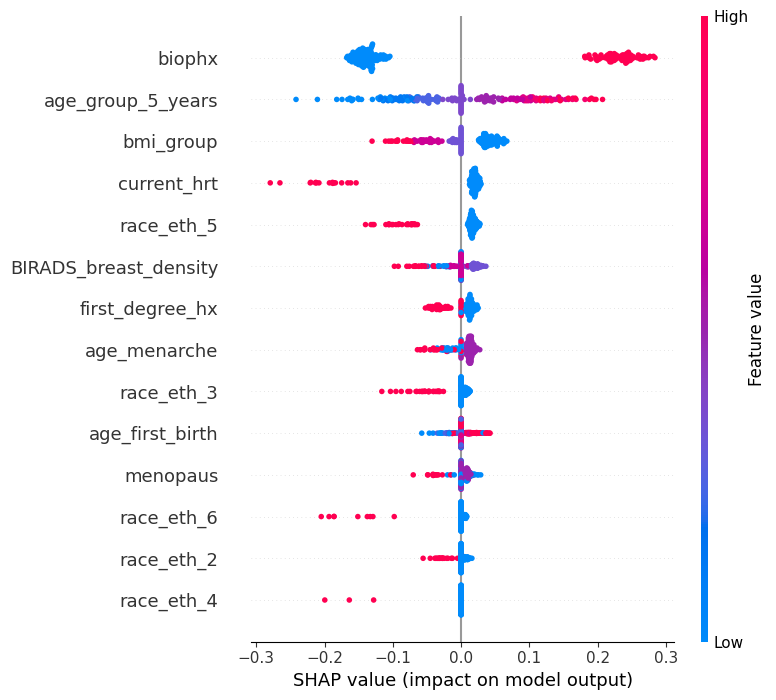

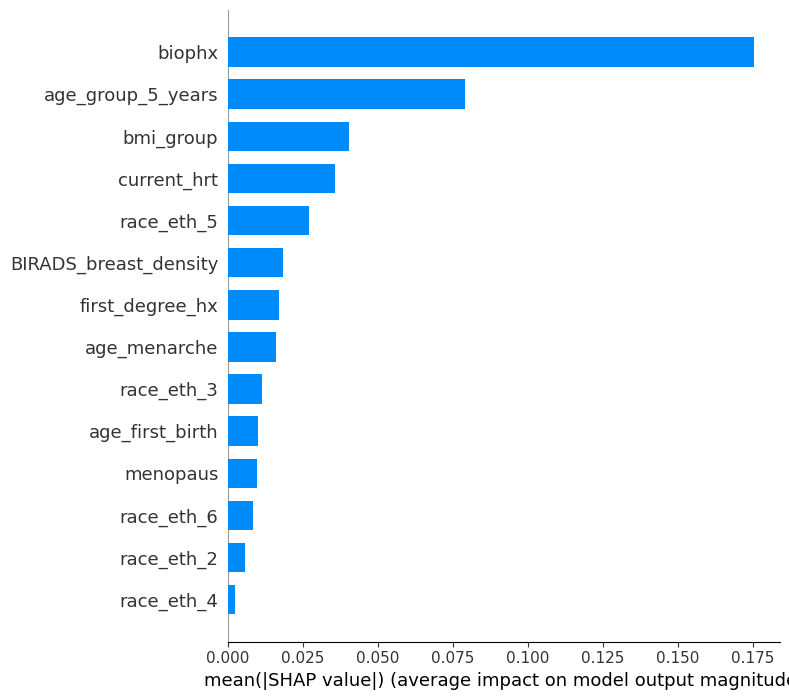

In [ ]:
# 2-CLASS EXPLAINABILITY: SHAP

background_2c = X_tr.sample(200, random_state=42)

explainer_2c = shap.KernelExplainer(
    model.predict,
    background_2c.values
)

X_val_sample_2c = X_val.sample(200, random_state=42)

shap_values_raw = explainer_2c.shap_values(X_val_sample_2c.values)

if isinstance(shap_values_raw, list):
    shap_values_raw = shap_values_raw[0]

if shap_values_raw.ndim == 3 and shap_values_raw.shape[2] == 1:
    shap_values_2c = shap_values_raw[:, :, 0]
else:
    shap_values_2c = shap_values_raw

# SHAP plot
shap.summary_plot(
    shap_values_2c,
    X_val_sample_2c,
    feature_names=X_val_sample_2c.columns
)

# SHAP bar plot
shap.summary_plot(
    shap_values_2c,
    X_val_sample_2c,
    feature_names=X_val_sample_2c.columns,
    plot_type="bar"
)

## Three-class classification

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

df_1 = pd.read_csv('../data/bcsc_risk_factors_summarized1_092020.csv')
df_2 = pd.read_csv('../data/bcsc_risk_factors_summarized2_092020.csv')
df_3 = pd.read_csv('../data/bcsc_risk_factors_summarized3_092020.csv')

df = pd.concat([df_1, df_2, df_3], ignore_index=True)

df = df.drop(columns=['year', 'count'])
df = df.astype('category')

cols_except_age = df.columns[df.columns != 'age_group_5_years']
df[cols_except_age] = df[cols_except_age].replace(9, np.nan)

df = df.dropna(subset=['breast_cancer_history'])

# Fill NaNs with mode
for col in df.columns:
    if col != 'breast_cancer_history':
        df[col].fillna(df[col].mode()[0], inplace=True)

# One-hot encoding (race only)
df = pd.get_dummies(df, columns=['race_eth'], drop_first=True)

# Convert bools to ints
bool_cols = df.select_dtypes('bool').columns
df[bool_cols] = df[bool_cols].astype(int)

# Logistic regression to build borderline class
y_bin = df['breast_cancer_history'].astype('int32')
X_logit = df.drop(columns=['breast_cancer_history'])

logit = LogisticRegression(max_iter=5000)
logit.fit(X_logit, y_bin)

df['pred_prob'] = logit.predict_proba(X_logit)[:, 1]

df['breast_cancer_history_3class'] = y_bin.copy()

lower = 0.30
upper = 0.50

mask2 = (
    (df['breast_cancer_history_3class'] == 0) &
    (df['pred_prob'] >= lower) &
    (df['pred_prob'] <= upper)
)

df.loc[mask2, 'breast_cancer_history_3class'] = 2

df_model = df.drop(columns=['breast_cancer_history', 'pred_prob'])

y = df_model['breast_cancer_history_3class'].astype('int32')
X = df_model.drop(columns=['breast_cancer_history_3class']).astype('float32')

print("Final X:", X.shape)
print("Final y:", y.value_counts())

Saving bcsc_risk_factors_summarized1_092020.csv to bcsc_risk_factors_summarized1_092020.csv
Saving bcsc_risk_factors_summarized3_092020.csv to bcsc_risk_factors_summarized3_092020.csv
Saving bcsc_risk_factors_summarized2_092020.csv to bcsc_risk_factors_summarized2_092020.csv


Final X: (1191438, 14)
Final y: breast_cancer_history_3class
0    843140
1    221776
2    126522
Name: count, dtype: int64


In [ ]:
# 3-Class Optuna

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, recall_score

import optuna

# Splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

classes = np.unique(y_tr)
class_weight = {int(c): w for c, w in zip(
    classes,
    compute_class_weight(class_weight='balanced', classes=classes, y=y_tr)
)}

input_dim = X_tr.shape[1]
n_classes = len(classes)

def objective(trial):
    tf.keras.backend.clear_session()

    n1 = trial.suggest_int("n1", 64, 256, step=64)
    n2 = trial.suggest_int("n2", 32, 128, step=32)
    d1 = trial.suggest_float("d1", 0.1, 0.5)
    d2 = trial.suggest_float("d2", 0.1, 0.5)
    bs = trial.suggest_categorical("bs", [128, 256, 512])

    model = Sequential([
        Dense(n1, activation='relu', input_dim=input_dim),
        Dropout(d1),
        Dense(n2, activation='relu'),
        Dropout(d2),
        Dense(n_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    es = EarlyStopping(monitor='val_loss', patience=5,
                       restore_best_weights=True)

    model.fit(X_tr, y_tr,
              validation_data=(X_val, y_val),
              epochs=100,
              batch_size=bs,
              callbacks=[es],
              class_weight=class_weight,
              verbose=0)

    y_val_pred = model.predict(X_val, verbose=0).argmax(axis=1)

    return recall_score(y_val, y_val_pred,
                        average='macro',
                        zero_division=0)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

best_params = study.best_params
print(best_params)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.7/404.7 kB 20.2 MB/s eta 0:00:00


{'n1': 192, 'n2': 96, 'd1': 0.19693312650350078, 'd2': 0.4681757710739912, 'bs': 128}


In [ ]:
tf.keras.backend.clear_session()

model = Sequential([
    Dense(best_params["n1"], activation='relu', input_dim=input_dim),
    Dropout(best_params["d1"]),
    Dense(best_params["n2"], activation='relu'),
    Dropout(best_params["d2"]),
    Dense(n_classes, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

es = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=best_params["bs"],
    callbacks=[es],
    class_weight=class_weight,
    verbose=1
)

Epoch 1/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 57s 9ms/step - accuracy: 0.6133 - loss: 0.9071 - val_accuracy: 0.7532 - val_loss: 0.5638
Epoch 2/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 32s 5ms/step - accuracy: 0.7393 - loss: 0.6597 - val_accuracy: 0.7397 - val_loss: 0.5442
Epoch 3/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - accuracy: 0.7487 - loss: 0.6087 - val_accuracy: 0.7509 - val_loss: 0.5029
Epoch 4/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 30s 5ms/step - accuracy: 0.7511 - loss: 0.5892 - val_accuracy: 0.7561 - val_loss: 0.4920
Epoch 5/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 28s 5ms/step - accuracy: 0.7500 - loss: 0.5788 - val_accuracy: 0.7548 - val_loss: 0.4982
Epoch 6/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 28s 5ms/step - accuracy: 0.7503 - loss: 0.5715 - val_accuracy: 0.7295 - val_loss: 0.5101
Epoch 7/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 33s 5ms/step - accuracy: 0.7491 - loss: 0.5683 - val_accuracy: 0.7606 - val_loss: 0.4800
Epoch 8/200
5958/5958 ━━━━━━━━━━━━━━━━━━━━ 45s 6ms/step - accuracy: 0.7490 -

In [ ]:
# Validation
y_val_pred = model.predict(X_val).argmax(axis=1)
print("VAL REPORT")
print(classification_report(y_val, y_val_pred))
print(confusion_matrix(y_val, y_val_pred))

# Test
y_test_proba = model.predict(X_test)
y_test_pred = y_test_proba.argmax(axis=1)

print("TEST REPORT")
print(classification_report(y_test, y_test_pred))
print(confusion_matrix(y_test, y_test_pred))

5958/5958 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step
VAL REPORT
              precision    recall  f1-score   support

           0       0.93      0.83      0.87    134902
           1       0.37      0.39      0.38     35484
           2       0.61      0.98      0.75     20244

    accuracy                           0.76    190630
   macro avg       0.63      0.73      0.67    190630
weighted avg       0.79      0.76      0.77    190630

[[111483  23245    174]
 [  9014  13744  12726]
 [     0    471  19773]]
7447/7447 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step
TEST REPORT
              precision    recall  f1-score   support

           0       0.92      0.83      0.87    168628
           1       0.36      0.38      0.37     44355
           2       0.60      0.98      0.75     25305

    accuracy                           0.76    238288
   macro avg       0.63      0.73      0.66    238288
weighted avg       0.79      0.76      0.77    238288

[[139206  29222    200]
 [ 11291  17069  15995]
 [    

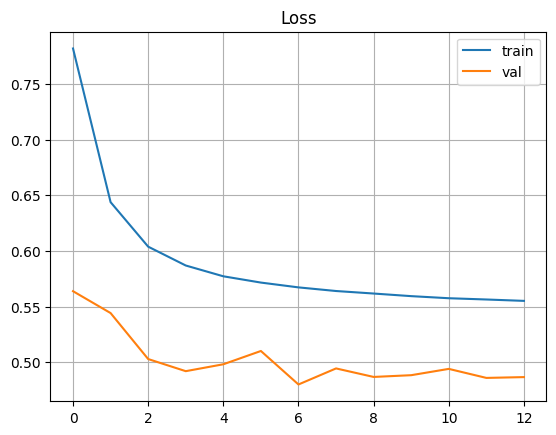

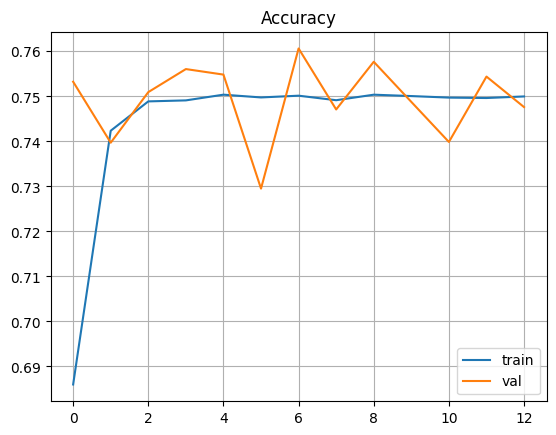

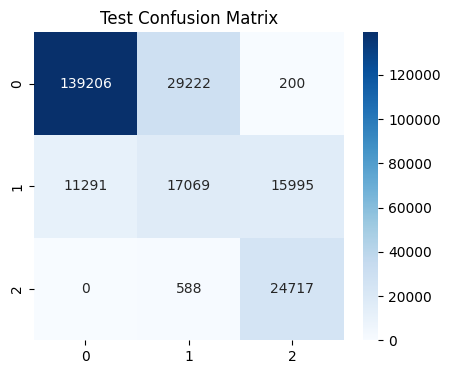

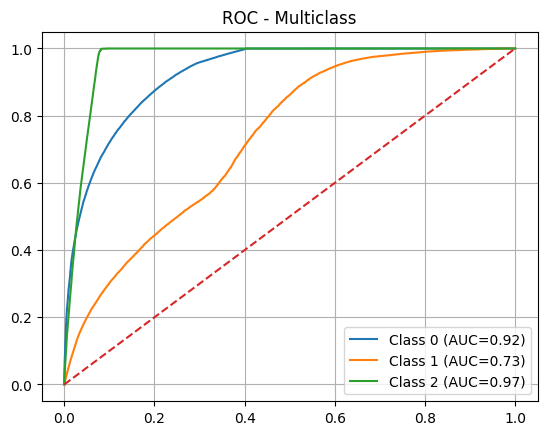

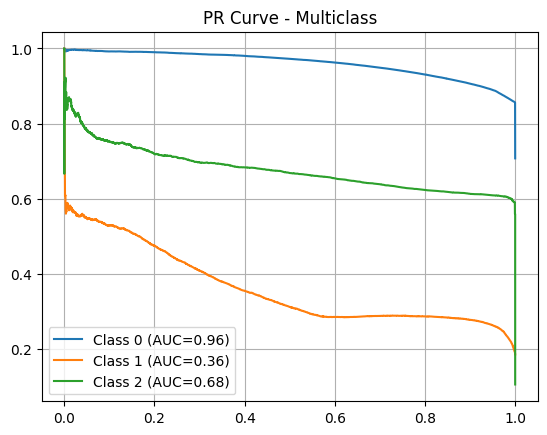

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# Training curves
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Loss")
plt.legend(["train","val"])
plt.grid()
plt.show()

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Accuracy")
plt.legend(["train","val"])
plt.grid()
plt.show()

# Confusion Matrix
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_test_pred),
            annot=True, cmap='Blues', fmt='d')
plt.title('Test Confusion Matrix')
plt.show()

for c in range(n_classes):
    y_true_bin = (y_test == c).astype(int)
    y_prob_bin = y_test_proba[:, c]

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true_bin, y_prob_bin)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'Class {c} (AUC={roc_auc:.2f})')

plt.plot([0,1],[0,1],'--')
plt.title("ROC - Multiclass")
plt.legend()
plt.grid()
plt.show()

# PR curve
for c in range(n_classes):
    y_true_bin = (y_test == c).astype(int)
    y_prob_bin = y_test_proba[:, c]

    prec, rec, _ = precision_recall_curve(y_true_bin, y_prob_bin)
    pr_auc = auc(rec, prec)

    plt.plot(rec, prec, label=f'Class {c} (AUC={pr_auc:.2f})')

plt.title("PR Curve - Multiclass")
plt.legend()
plt.grid()
plt.show()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


  0%|          | 0/200 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 17s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 17s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 17s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
... (training log trimmed) ...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 17s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 18s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 19s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
12975/12975 ━━━━━━━━━━━━━━━━━━━━ 18s 1ms/step
1/1 ━━

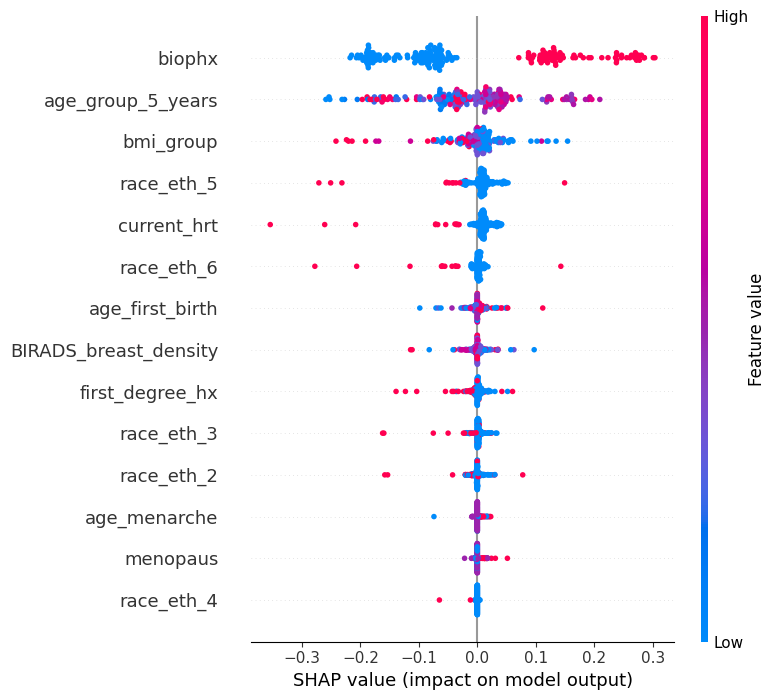

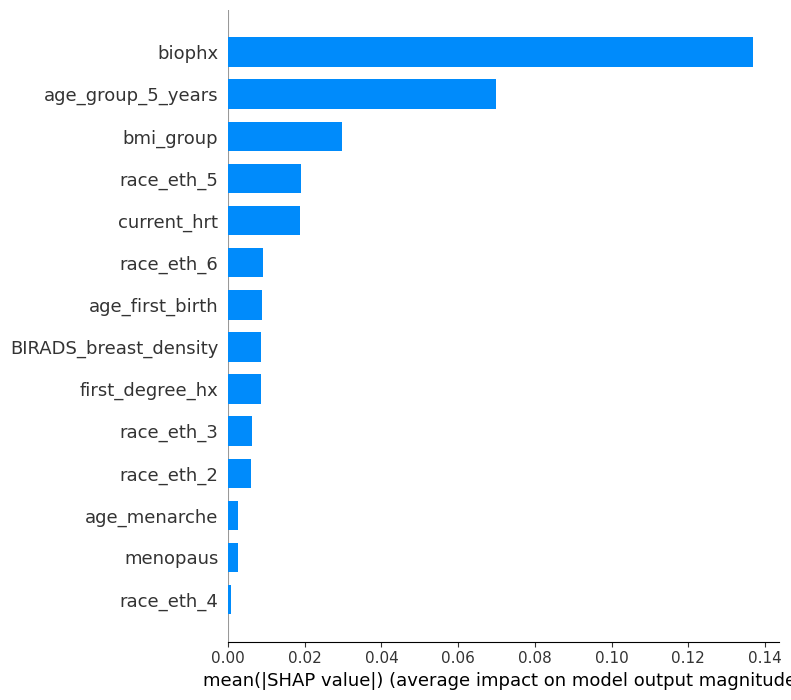

In [ ]:
# SHAP for 3-class model

import shap

background_3c = X_tr.sample(200, random_state=42)
X_val_sample_3c = X_val.sample(200, random_state=42)

explainer_3c = shap.KernelExplainer(model.predict, background_3c.values)

shap_vals_3c = explainer_3c.shap_values(X_val_sample_3c.values)

shap_vals_class2 = shap_vals_3c[:, :, 2]

# class 2 (high-risk group)
shap.summary_plot(
    shap_vals_class2,
    X_val_sample_3c,
    feature_names=X_val_sample_3c.columns
)

# Bar
shap.summary_plot(
    shap_vals_class2,
    X_val_sample_3c,
    feature_names=X_val_sample_3c.columns,
    plot_type='bar'
)